# Agrupamiento de estaciones para P3 — MiBici

**Proyecto:** TC5061 · Equipo 52 · Pregunta P3 (agrupamiento)
**Autor:** Joel Sánchez · **Rama:** `feature/p3-clustering`

**Propósito.** Con la matriz estación × característica del notebook `2.0`, decidir el número de grupos, comparar algoritmos y verificar que el resultado sea estable. Las decisiones tomadas aquí (k, algoritmo principal, métricas) son las que registra `equipo52_module/modeling/train_p3.py` en MLflow.

**Fuente.** La misma del notebook `2.0`: `data/interim/viajes.parquet` (ingesta del equipo) y la nomenclatura de septiembre de 2026.

**Datos personales.** No se usan ni se leen columnas de usuario, género ni año de nacimiento.

In [1]:
# Objetivo: preparar el entorno y reconstruir la matriz del notebook 2.0.
# Resultado esperado: matriz de estaciones lista y su forma (estaciones × características).

%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import HDBSCAN, AgglomerativeClustering, KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(Path.cwd().parent))
from equipo52_module.config import (
    DURACION_MINIMA_SEGUNDOS, ESTACIONES_EXCLUIDAS, FECHA_FIN,
    NOMENCLATURA_FILE, SEED, VIAJES_FILE,
)
from equipo52_module.features import construir_matriz_p3, quitar_viajes_cortos

nomenclatura = pd.read_csv(NOMENCLATURA_FILE).rename(
    columns={"id": "estacion_id", "dpcapacity": "capacidad",
             "latitude": "latitud", "longitude": "longitud"})
estaciones = (nomenclatura[~nomenclatura["estacion_id"].isin(ESTACIONES_EXCLUIDAS)
                           & (nomenclatura["capacidad"] > 0)]
              .set_index("estacion_id")[["capacidad", "latitud", "longitud"]])

viajes = quitar_viajes_cortos(pd.read_parquet(VIAJES_FILE), DURACION_MINIMA_SEGUNDOS)
matriz = construir_matriz_p3(viajes, estaciones, pd.Timestamp(FECHA_FIN))

GEO = ["latitud", "longitud"]
columnas = [c for c in matriz.columns if c not in GEO]
escalador = StandardScaler().fit(matriz[columnas])
X = escalador.transform(matriz[columnas])
print(f"Matriz: {X.shape[0]} estaciones × {X.shape[1]} características estandarizadas")

2026-10-17 16:07:13.448 | INFO     | equipo52_module.config:<module>:11 - PROJ_ROOT path is: /Users/pittjr/JSO_DEV/ITESM/MAESTRIA_IA/3rdTrim/TC5061-Proyecto-Equipo52


Matriz: 469 estaciones × 42 características estandarizadas


## 1. Línea base: agrupar solo por ubicación

La solución ingenua: K-Means con k = 5 sobre latitud y longitud, como trazar zonas a mano en el mapa. Su silueta se calcula **en el espacio de características de uso**: dice si las zonas geográficas también son coherentes en comportamiento. Si un modelo sobre características no la supera, no aporta nada.

Silueta (en espacio de uso): 0.019
Davies-Bouldin: 3.267
Calinski-Harabasz: 20.9


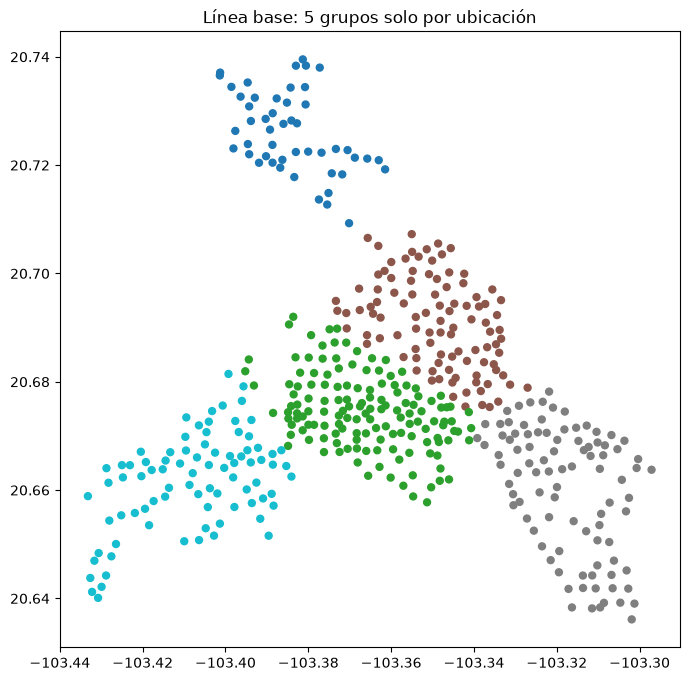

In [2]:
# Objetivo: ajustar la línea base geográfica y evaluarla en el espacio de uso.
# Resultado esperado: silueta, Davies-Bouldin y Calinski-Harabasz de la partición geográfica
# medida con las características de uso; y el mapa de las 5 zonas.

X_geo = StandardScaler().fit_transform(matriz[GEO])
geo = KMeans(n_clusters=5, n_init=20, random_state=SEED).fit(X_geo)
print("Silueta (en espacio de uso):", round(silhouette_score(X, geo.labels_), 3))
print("Davies-Bouldin:", round(davies_bouldin_score(X, geo.labels_), 3))
print("Calinski-Harabasz:", round(calinski_harabasz_score(X, geo.labels_), 1))

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(matriz["longitud"], matriz["latitud"], c=geo.labels_, cmap="tab10", s=25)
ax.set_title("Línea base: 5 grupos solo por ubicación");

## 2. Número de grupos

Barrido de k = 2…12 para K-Means. El k con mayor silueta es el candidato; el dendrograma de Ward (sección 4) sirve de contraste estructural.

,k,silueta
0,2,0.150655
1,3,0.091648
2,4,0.105200
3,5,0.063878
4,6,0.064869
5,7,0.071434
6,8,0.086823
7,9,0.072754
8,10,0.052526
9,11,0.072789


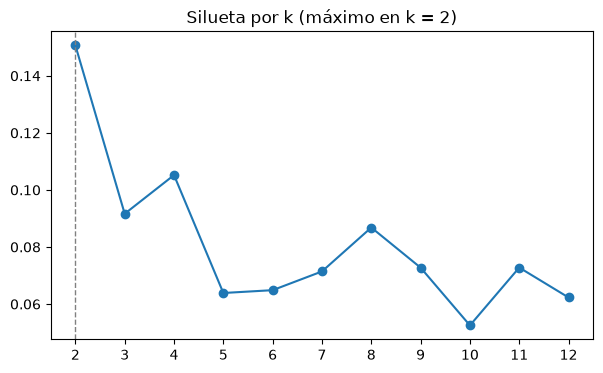

In [3]:
# Objetivo: medir la silueta de K-Means para cada k entre 2 y 12.
# Resultado esperado: gráfica de silueta por k con el máximo marcado.

barrido = []
for k in range(2, 13):
    etiquetas = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(X)
    barrido.append({"k": k, "silueta": silhouette_score(X, etiquetas)})
barrido = pd.DataFrame(barrido)

mejor_k = int(barrido.loc[barrido["silueta"].idxmax(), "k"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(barrido["k"], barrido["silueta"], marker="o")
ax.axvline(mejor_k, color="gray", ls="--", lw=1)
ax.set_xticks(barrido["k"])
ax.set_title(f"Silueta por k (máximo en k = {mejor_k})");
barrido

## 3. K-Means sobre las características de uso

El candidato principal: sus centroides se pueden leer en lenguaje de negocio («este grupo saca el 34 % de sus viajes entre 7 y 9 h»), que es lo que consume el equipo de planeación.

Silueta: 0.151
Davies-Bouldin: 2.309
Calinski-Harabasz: 75.2


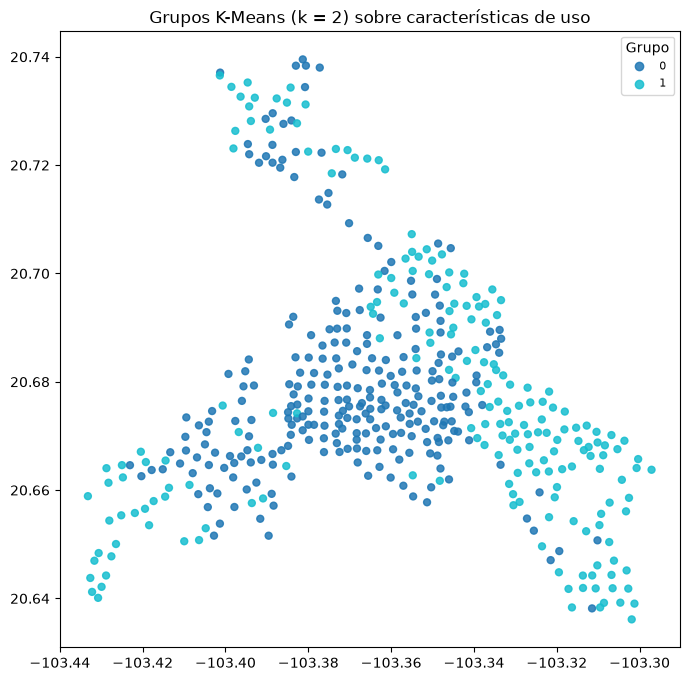

In [4]:
# Objetivo: ajustar K-Means con el k elegido y evaluarlo.
# Resultado esperado: las tres métricas internas del candidato y el mapa de grupos.

km = KMeans(n_clusters=mejor_k, n_init=20, random_state=SEED).fit(X)
print("Silueta:", round(silhouette_score(X, km.labels_), 3))
print("Davies-Bouldin:", round(davies_bouldin_score(X, km.labels_), 3))
print("Calinski-Harabasz:", round(calinski_harabasz_score(X, km.labels_), 1))

fig, ax = plt.subplots(figsize=(8, 8))
puntos = ax.scatter(matriz["longitud"], matriz["latitud"], c=km.labels_,
                    cmap="tab10", s=25, alpha=0.85)
ax.legend(*puntos.legend_elements(), title="Grupo", fontsize=8)
ax.set_title(f"Grupos K-Means (k = {mejor_k}) sobre características de uso");

,salidas_por_mes,viajes_por_anclaje_mes,balance,prop_viajes_redondos,duracion_mediana_min,meses_activa,share_viajes_ultimos_12m,estaciones,prop_fin_semana,hora_pico
grupo,,,,,,,,,,
0,1060.060,123.817,-0.026,0.040,10.376,109.844,0.193,270,50.129,18
1,322.387,38.616,-0.008,0.054,9.783,44.824,0.551,199,47.842,8


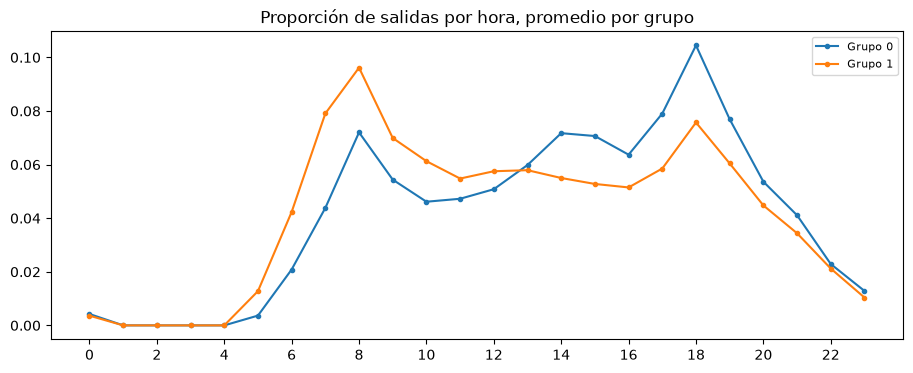

In [5]:
# Objetivo: leer los grupos en lenguaje de negocio.
# Resultado esperado: perfil horario promedio por grupo y tabla descriptiva
# (tamaño, actividad, balance, fin de semana, recreación, antigüedad).

horas = matriz.assign(grupo=km.labels_).groupby("grupo")[[f"h{h:02d}" for h in range(24)]].mean()
fig, ax = plt.subplots(figsize=(11, 4))
for grupo, fila in horas.iterrows():
    ax.plot(range(24), fila.to_numpy(), marker="o", ms=3, label=f"Grupo {grupo}")
ax.set_xticks(range(0, 24, 2))
ax.set_title("Proporción de salidas por hora, promedio por grupo")
ax.legend(fontsize=8);

descripcion = matriz.assign(grupo=km.labels_).groupby("grupo")[
    ["salidas_por_mes", "viajes_por_anclaje_mes", "balance", "prop_viajes_redondos",
     "duracion_mediana_min", "meses_activa", "share_viajes_ultimos_12m"]].mean().round(3)
descripcion["estaciones"] = np.bincount(km.labels_)
descripcion["prop_fin_semana"] = (matriz.assign(grupo=km.labels_)
                                .groupby("grupo")[["d5", "d6"]].sum().sum(axis=1).round(3))
descripcion["hora_pico"] = horas.idxmax(axis=1).str[1:].astype(int)
descripcion

## 4. Ward: contraste de estructura

El agrupamiento jerárquico no asume grupos esféricos y su dendrograma muestra la estructura anidada. Si Ward y K-Means asignan casi igual al mismo k (ARI alto), el resultado es robusto al algoritmo.

Silueta Ward: 0.129
ARI Ward vs K-Means: 0.565


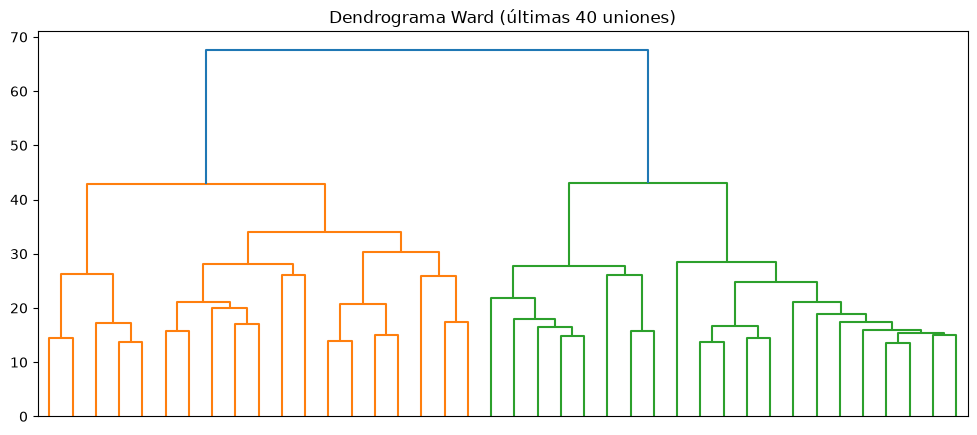

In [6]:
# Objetivo: comparar Ward contra K-Means al mismo k y ver su dendrograma.
# Resultado esperado: ARI entre las dos asignaciones y el dendrograma truncado.

ward = AgglomerativeClustering(n_clusters=mejor_k, linkage="ward").fit_predict(X)
print("Silueta Ward:", round(silhouette_score(X, ward), 3))
print("ARI Ward vs K-Means:", round(adjusted_rand_score(ward, km.labels_), 3))

fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(linkage(X, method="ward"), truncate_mode="lastp", p=40,
           no_labels=True, ax=ax)
ax.set_title("Dendrograma Ward (últimas 40 uniones)");

## 5. HDBSCAN: estaciones que no encajan

Diagnóstico complementario: HDBSCAN no obliga a cada estación a pertenecer a un grupo; las que marca como ruido (−1) son comportamientos atípicos que el operador conviene revisar de forma individual.

In [7]:
# Objetivo: detectar grupos densos y estaciones anómalas con HDBSCAN.
# Resultado esperado: con min_cluster_size = 15 no se espera grupo alguno (se verifica);
# con 5, un núcleo pequeño denso y el resto marcado como ruido, lo que mostraría que los
# patrones de uso forman un continuo y no islas separadas.

for min_size in (15, 5):
    hdb = HDBSCAN(min_cluster_size=min_size).fit_predict(X)
    nucleo = hdb >= 0
    grupos = int(hdb[nucleo].max() + 1) if nucleo.any() else 0
    print(f"min_cluster_size = {min_size}: {grupos} grupos, "
          f"ruido {round((~nucleo).mean(), 3)}")
    if grupos >= 2:
        print("  Silueta (solo núcleo):",
              round(silhouette_score(X[nucleo], hdb[nucleo]), 3))
        anomalas = matriz.index[~nucleo]
        print(f"  {len(anomalas)} estaciones atípicas (muestra):",
              sorted(anomalas.tolist())[:15])

min_cluster_size = 15: 0 grupos, ruido 1.0
min_cluster_size = 5: 2 grupos, ruido 0.957
  Silueta (solo núcleo): 0.376
  449 estaciones atípicas (muestra): [2, 3, 4, 5, 6, 8, 9, 10, 11, 12, 15, 18, 19, 20, 21]


/Users/pittjr/JSO_DEV/ITESM/MAESTRIA_IA/3rdTrim/TC5061-Proyecto-Equipo52/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/Users/pittjr/JSO_DEV/ITESM/MAESTRIA_IA/3rdTrim/TC5061-Proyecto-Equipo52/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


## 6. Estabilidad entre eras

¿Los grupos son un artefacto del periodo o describen roles que persisten? Se recalcula la matriz con los viajes de dos eras disjuntas (2014-12 a 2020-08 y 2020-09 a 2026-09), se aplica el mismo escalador y modelo ya ajustados, y se compara la asignación de las estaciones activas en ambas con el ARI.

In [8]:
# Objetivo: medir la estabilidad temporal de la asignación de grupos.
# Resultado esperado: ARI entre la asignación de la era A y la de la era B, y cuántas
# estaciones participan en la comparación.

corte = pd.Timestamp("2020-09-01")
matriz_a = construir_matriz_p3(viajes[viajes["Inicio_del_viaje"] < corte],
                               estaciones, corte - pd.Timedelta(days=1))
matriz_b = construir_matriz_p3(viajes[viajes["Inicio_del_viaje"] >= corte],
                               estaciones, pd.Timestamp(FECHA_FIN))
comunes = matriz_a.index.intersection(matriz_b.index)
ari = adjusted_rand_score(km.predict(escalador.transform(matriz_a.loc[comunes, columnas])),
                          km.predict(escalador.transform(matriz_b.loc[comunes, columnas])))
print(f"Estaciones activas en ambas eras: {len(comunes)}")
print("ARI entre eras:", round(ari, 3))

Estaciones activas en ambas eras: 274
ARI entre eras: 0.618


### Conclusiones y lo que pasa a `train_p3.py`

- **k** se elige por el máximo de silueta del barrido 2-12 (registrado como parámetro); el dendrograma de Ward queda como evidencia visual de la estructura.
- **Candidato principal:** K-Means sobre las características de uso, por centroides interpretables y asignación completa; **contraste:** Ward al mismo k con ARI de concordancia; **diagnóstico:** HDBSCAN para estaciones atípicas.
- **Línea base:** K-Means geográfico con k = 5 evaluado en el espacio de uso; el candidato debe superarla en silueta para aportar valor sobre un mapa dibujado a mano.
- **Validación:** métricas internas (`hist_silhouette`, `hist_davies_bouldin`, `hist_calinski_harabasz`), `estabilidad_eras_ari`, `estabilidad_bootstrap_ari` y `concordancia_ward_kmeans_ari`, todas registradas en MLflow por `train_p3.py` junto con el mapa, los perfiles horarios y la descripción de grupos.